<div align="center">

# Aplicação de Ciência de Dados na Indústria 4.0
## Previsão de Demanda para o Planejamento da Produção

**Centro Universitário Católica de Santa Catarina**

Disciplina: **Inteligência Artificial** — Avaliação N2 (Ciência de Dados)

Professor: **Claudinei Dias (Ney)**

Alunos: **Rodrigo Klappoth** e **Henrique Klappoth**

</div>

---

### Como executar este notebook

Este notebook é autocontido e reprodutível. Ele procura o arquivo de dados em `dados/demanda_diaria.csv`
e, caso não o encontre (por exemplo, ao ser aberto diretamente no Google Colab), faz o download
automático da mesma base a partir do repositório público. Basta executar as células na ordem
(`Executar tudo`). Tempo total de execução: cerca de 1 a 3 minutos.

---
# 1. Introdução

## 1.1 A Indústria 4.0 e sua importância no cenário atual

A chamada **Quarta Revolução Industrial (Indústria 4.0)** é caracterizada pela fusão entre o mundo
físico da produção e o mundo digital dos dados. Sensores embarcados, sistemas ciberfísicos,
Internet das Coisas Industrial (IIoT), computação em nuvem e inteligência artificial passam a operar
de forma integrada, permitindo que a fábrica deixe de ser apenas *automatizada* para tornar-se
**conectada, instrumentada e capaz de tomar decisões baseadas em dados**.

Entre os pilares tecnológicos usualmente associados ao conceito estão: IoT industrial, Big Data e
Analytics, computação em nuvem, manufatura aditiva, robótica colaborativa, simulação / gêmeos digitais,
integração horizontal e vertical de sistemas, realidade aumentada e segurança cibernética.

O pilar diretamente explorado neste trabalho é o de **Big Data e Analytics**. Em uma planta industrial
conectada, o volume de dados gerado (ordens de produção, apontamentos de chão de fábrica, expedição,
demanda dos centros de distribuição) só se converte em vantagem competitiva quando é transformado em
**previsão** e, a partir dela, em **decisão**. É justamente esse o ciclo que este trabalho procura
demonstrar de ponta a ponta: dado bruto → modelo → decisão de planejamento.

## 1.2 Definição do problema

Em qualquer operação industrial, o **Plano Mestre de Produção (MPS — *Master Production Schedule*)**
responde a três perguntas: *o que* produzir, *quanto* produzir e *quando* produzir. A qualidade dessa
resposta depende quase inteiramente de uma estimativa: **qual será a demanda nos próximos meses**.

O problema é economicamente assimétrico e caro nos dois sentidos:

| Erro de previsão | Consequência operacional |
|---|---|
| **Subestimar a demanda** | Ruptura de estoque, perda de venda, horas extras, fretes emergenciais, quebra de contrato de nível de serviço |
| **Superestimar a demanda** | Capital de giro parado em estoque, custo de armazenagem, obsolescência, ociosidade planejada de forma errada |

Na prática, muitas empresas ainda planejam com regras simples do tipo *"produzir o mesmo volume do ano
passado"* ou *"usar a média dos últimos doze meses"*. Essas heurísticas ignoram simultaneamente a
tendência de crescimento, a sazonalidade anual, o padrão semanal e as diferenças de comportamento entre
produtos e entre unidades.

**Problema a ser abordado:** *construir um modelo de previsão de demanda, em nível de SKU e unidade
fabril, com horizonte de 90 dias (um trimestre de planejamento), capaz de superar de forma mensurável
as regras heurísticas hoje utilizadas no planejamento da produção.*

O horizonte de **90 dias** não é arbitrário: corresponde ao ciclo trimestral de S&OP
(*Sales and Operations Planning*) e é compatível com o *lead time* de compra de matéria-prima e de
contratação/realocação de mão de obra. Essa escolha tem uma consequência metodológica importante,
detalhada na Seção 3.3: o modelo **só pode usar informações disponíveis com pelo menos 90 dias de
antecedência**.

## 1.3 Objetivos do trabalho

**Objetivo geral**

Aplicar o ciclo completo de ciência de dados — coleta, preparação, modelagem e análise — sobre uma base
real de demanda diária, entregando um modelo preditivo que apoie a decisão de planejamento da produção
em um contexto de Indústria 4.0.

**Objetivos específicos**

1. Coletar e avaliar a qualidade de uma base real com mais de 900 mil registros de demanda diária.
2. Caracterizar, por meio de análise exploratória, os componentes da série: tendência, sazonalidade
   anual, sazonalidade semanal e variabilidade entre produtos e unidades.
3. Construir atributos (*feature engineering*) compatíveis com um horizonte de previsão de 90 dias,
   sem vazamento de informação futura.
4. Implementar e comparar, em Python, quatro abordagens: duas heurísticas de referência (*baselines*),
   um modelo linear regularizado e um modelo de *ensemble* baseado em árvores.
5. Avaliar os modelos com validação temporal (*hold-out* e *rolling origin*) e métricas adequadas à
   previsão de demanda (MAE, RMSE, WMAPE e SMAPE).
6. Traduzir o resultado estatístico em **decisão industrial**: plano de produção agregado e
   dimensionamento de estoque de segurança.
7. Discutir criticamente a eficácia, as limitações e os caminhos de evolução da solução proposta.

---
# 2. Metodologia

## 2.1 Descrição dos dados utilizados

| Característica | Descrição |
|---|---|
| **Fonte** | *Store Item Demand Forecasting Challenge* (Kaggle, 2018) — base pública amplamente utilizada como *benchmark* de previsão de demanda. Cópia utilizada: repositório público no GitHub (link na Seção 5). |
| **Volume** | **913.000 registros**, aproximadamente 17 MB |
| **Período** | 01/01/2013 a 31/12/2017 (**5 anos**, 1.826 dias) |
| **Granularidade** | 1 registro por dia × unidade × SKU |
| **Entidades** | **10 unidades** (centros de distribuição / plantas) × **50 SKUs** = 500 séries temporais |
| **Tipos de dados** | `data` (temporal), `unidade` (categórico), `sku` (categórico), `demanda` (numérico discreto, contagem) |
| **Variável-alvo** | `demanda` — unidades demandadas no dia |

**Observação sobre a adequação da base ao contexto industrial.** A base é originalmente registrada como
demanda de itens em pontos de venda. Essa demanda é exatamente o sinal que alimenta, a montante, o
planejamento de produção: é a *demanda independente* que, explodida pela lista de materiais (BOM) no
MRP, gera as ordens de produção e de compra. Para os fins deste trabalho, cada `unidade` é tratada como
um **centro de distribuição atendido por uma planta** e cada `sku` como um **item acabado produzido**.
Optou-se por uma base **real e verificável** em vez de dados sintéticos, de modo que os padrões
observados (tendência, sazonalidade, ruído) sejam genuínos e os resultados, reprodutíveis por terceiros.

## 2.2 Processos de coleta e preparação dos dados

1. **Coleta** — download programático do arquivo CSV a partir de URL pública (reprodutível em qualquer
   ambiente, inclusive Google Colab), com cache local.
2. **Verificação de qualidade** — checagem de valores ausentes, duplicidades na chave
   (`data`, `unidade`, `sku`), continuidade do calendário, tipos e faixa de valores.
3. **Padronização** — tradução dos nomes de colunas para português e conversão da coluna de data para
   o tipo `datetime`.
4. **Ordenação e indexação** — ordenação por (`unidade`, `sku`, `data`), condição necessária para o
   cálculo correto de defasagens dentro de cada série.
5. **Engenharia de atributos** — criação de variáveis de calendário, defasagens (*lags*) e estatísticas
   móveis, todas respeitando o horizonte de 90 dias.
6. **Particionamento temporal** — separação treino/teste **por tempo**, nunca aleatória.

## 2.3 Ferramentas e técnicas de modelagem de dados

**Ferramentas:** Python 3, `pandas` (manipulação), `NumPy` (computação numérica),
`Matplotlib` (visualização), `statsmodels` (decomposição de séries temporais) e
`scikit-learn` (modelagem e avaliação). Ambiente: Jupyter Notebook / Google Colab.

**Técnicas de modelagem.** A estratégia adotada é a de **modelo global**: em vez de ajustar 500 modelos
univariados independentes (um por série), transforma-se o problema de previsão em um problema de
**regressão supervisionada tabular**, no qual uma única função aprende o padrão comum a todas as séries
usando identificadores e atributos temporais. Essa abordagem é hoje padrão em previsão de demanda em
larga escala, pois compartilha informação entre séries curtas ou ruidosas e reduz drasticamente o custo
de manutenção do modelo em produção.

| Modelo | Papel | Justificativa |
|---|---|---|
| **Naïve sazonal (lag 364)** | *Baseline* | Formaliza a heurística "repetir o mesmo período do ano passado"; 364 = 52 semanas, preserva o dia da semana |
| **Média móvel de 364 dias** | *Baseline* | Formaliza a heurística "usar a média do último ano" |
| **Regressão Ridge** | Modelo linear | Interpretável, captura tendência linear e extrapola; regularização L2 lida com colinearidade entre *lags* |
| **Histogram Gradient Boosting** | *Ensemble* de árvores | Captura interações e não linearidades (ex.: efeito do dia da semana que varia por SKU); robusto a escalas distintas |

## 2.4 Métodos de análise de dados aplicados

**Análise exploratória:** decomposição clássica da série agregada (tendência / sazonalidade / resíduo),
análise de sazonalidade anual e semanal, mapa de calor mês × ano, distribuição da demanda e comparação
entre unidades e SKUs.

**Validação.** Em séries temporais, a validação aleatória (*k-fold* embaralhado) produz resultados
otimistas e falsos, pois permite que o modelo "veja o futuro" durante o treino. Utilizam-se aqui
duas estratégias estritamente temporais:

- ***Hold-out* temporal:** treino de 2013 a 2016 (4 anos), teste em 2017 (ano completo, 182.500 registros).
- ***Rolling origin* (origem móvel):** 4 janelas sucessivas de validação, verificando a estabilidade
  do desempenho ao longo do tempo.

**Métricas.** Sendo $y_i$ o valor real e $\hat{y}_i$ o previsto:

| Métrica | Fórmula | Interpretação |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum \lvert y_i-\hat{y}_i \rvert$ | Erro médio em unidades do produto |
| **RMSE** | $\sqrt{\frac{1}{n}\sum (y_i-\hat{y}_i)^2}$ | Penaliza erros grandes (rupturas severas) |
| **WMAPE** | $\frac{\sum \lvert y_i-\hat{y}_i \rvert}{\sum y_i}\times 100$ | Erro percentual ponderado pelo volume — métrica de referência em planejamento de demanda |
| **SMAPE** | $\frac{100}{n}\sum \frac{2\lvert y_i-\hat{y}_i\rvert}{\lvert y_i\rvert+\lvert \hat{y}_i\rvert}$ | Erro percentual simétrico, estável quando há valores baixos |

Optou-se pelo **WMAPE** como métrica principal, em lugar do MAPE tradicional: o MAPE é instável quando
a demanda se aproxima de zero (divisão por valores muito pequenos) e trata com o mesmo peso o erro em um
item de alto e de baixo giro — o que não corresponde ao impacto financeiro real na operação.

---
# 3. Desenvolvimento

## 3.1 Configuração do ambiente e carga dos dados

In [1]:
# Bibliotecas utilizadas em todo o trabalho
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings('ignore')
pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 30)

# Padrão visual único para todos os gráficos do trabalho
plt.rcParams.update({
    'figure.figsize': (11, 4.2), 'figure.dpi': 110, 'savefig.dpi': 130,
    'axes.grid': True, 'grid.alpha': 0.25, 'axes.spines.top': False,
    'axes.spines.right': False, 'font.size': 10, 'axes.titlesize': 12,
    'axes.titleweight': 'bold', 'figure.autolayout': True,
})
COR_REAL, COR_PREV, COR_AUX = '#1f3b6e', '#d1495b', '#8d99ae'

SEMENTE = 42
np.random.seed(SEMENTE)

os.makedirs('imagens', exist_ok=True)
print('Ambiente configurado | pandas', pd.__version__, '| numpy', np.__version__)

Ambiente configurado | pandas 3.0.5 | numpy 2.5.3


### Coleta dos dados

A célula abaixo implementa a etapa de **coleta**: utiliza a cópia local caso exista e, caso contrário,
realiza o download a partir da URL pública. Isso garante que o notebook execute tanto no repositório
clonado quanto diretamente no Google Colab.

In [2]:
CAMINHO_LOCAL = 'dados/demanda_diaria.csv'
URL_PUBLICA = ('https://raw.githubusercontent.com/ugursaricam/'
               'store-item-demand-forecasting/master/datasets/train.csv')

if os.path.exists(CAMINHO_LOCAL):
    origem = f'arquivo local ({CAMINHO_LOCAL})'
    bruto = pd.read_csv(CAMINHO_LOCAL, parse_dates=['date'])
else:
    origem = 'download da URL pública'
    bruto = pd.read_csv(URL_PUBLICA, parse_dates=['date'])
    os.makedirs('dados', exist_ok=True)
    bruto.to_csv(CAMINHO_LOCAL, index=False)   # cache local

# Padronização dos nomes das colunas para português
df = bruto.rename(columns={'date': 'data', 'store': 'unidade',
                           'item': 'sku', 'sales': 'demanda'})
df = df.sort_values(['unidade', 'sku', 'data']).reset_index(drop=True)

print(f'Origem dos dados : {origem}')
print(f'Dimensões        : {df.shape[0]:,} registros x {df.shape[1]} colunas'.replace(',', '.'))
df.head()

Origem dos dados : arquivo local (dados/demanda_diaria.csv)
Dimensões        : 913.000 registros x 4 colunas


,data,unidade,sku,demanda
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


### 3.2 Verificação da qualidade dos dados

Antes de qualquer análise, é preciso responder: *os dados são confiáveis?*

In [3]:
print('=' * 68)
print('RELATÓRIO DE QUALIDADE DOS DADOS')
print('=' * 68)

print('\n[1] Tipos de dados e memória')
df.info(memory_usage='deep')

print('\n[2] Valores ausentes por coluna')
print(df.isna().sum().to_string())

print('\n[3] Duplicidades na chave (data, unidade, sku)')
print(f'    Registros duplicados: {df.duplicated(["data", "unidade", "sku"]).sum()}')

print('\n[4] Cobertura temporal')
dias_esperados = (df.data.max() - df.data.min()).days + 1
print(f'    Período              : {df.data.min():%d/%m/%Y} a {df.data.max():%d/%m/%Y}')
print(f'    Dias no calendário   : {dias_esperados}')
print(f'    Dias distintos na base: {df.data.nunique()}')
print(f'    Dias faltantes       : {dias_esperados - df.data.nunique()}')

print('\n[5] Integridade do painel (todas as séries completas?)')
esperado = df.data.nunique() * df.unidade.nunique() * df.sku.nunique()
print(f'    Registros esperados  : {esperado:,}'.replace(',', '.'))
print(f'    Registros observados : {len(df):,}'.replace(',', '.'))
print(f'    Painel balanceado    : {esperado == len(df)}')

print('\n[6] Estatísticas da variável-alvo (demanda)')
print(df.demanda.describe().round(2).to_string())
print(f'    Valores negativos    : {(df.demanda < 0).sum()}')
print(f'    Dias com demanda zero: {(df.demanda == 0).sum()}')
print('=' * 68)

RELATÓRIO DE QUALIDADE DOS DADOS

[1] Tipos de dados e memória
<class 'pandas.DataFrame'>
RangeIndex: 913000 entries, 0 to 912999
Data columns (total 4 columns):
 #   Column   Non-Null Count   Dtype         
---  ------   --------------   -----         
 0   data     913000 non-null  datetime64[us]
 1   unidade  913000 non-null  int64         
 2   sku      913000 non-null  int64         
 3   demanda  913000 non-null  int64         
dtypes: datetime64[us](1), int64(3)
memory usage: 27.9 MB

[2] Valores ausentes por coluna
data       0
unidade    0
sku        0
demanda    0

[3] Duplicidades na chave (data, unidade, sku)
    Registros duplicados: 0

[4] Cobertura temporal
    Período              : 01/01/2013 a 31/12/2017
    Dias no calendário   : 1826
    Dias distintos na base: 1826
    Dias faltantes       : 0

[5] Integridade do painel (todas as séries completas?)
    Registros esperados  : 913.000
    Registros observados : 913.000
    Painel balanceado    : True

[6] Estatística

count    913000.00
mean         52.25
std          28.80
min           0.00
25%          30.00
50%          47.00
75%          70.00
max         231.00
    Valores negativos    : 0
    Dias com demanda zero: 1


**Conclusão da verificação de qualidade.** A base está em excelente estado: **não há valores ausentes,
duplicidades, datas faltantes ou valores negativos**, e o painel é **balanceado** — todas as 500 séries
(10 unidades × 50 SKUs) possuem observação para todos os 1.826 dias do período. Não há, portanto,
necessidade de imputação, remoção de registros ou reconstrução de calendário.

Essa constatação é importante também do ponto de vista metodológico: ela permite concentrar o esforço
na **modelagem**, e não na limpeza. Vale registrar, porém, que em uma base real extraída diretamente de
um ERP/MES o cenário costuma ser bem diferente — datas faltantes em feriados, apontamentos duplicados e
devoluções lançadas como quantidade negativa são ocorrências rotineiras, e a etapa de preparação
tipicamente consome a maior parte do tempo do projeto.

### 3.3 Análise exploratória dos dados (AED)

A análise exploratória tem dois objetivos: **entender o comportamento da demanda** e **orientar as
decisões de modelagem** — quais atributos criar, quais padrões o modelo precisa ser capaz de capturar.

#### 3.3.1 Visão agregada: a demanda total da planta

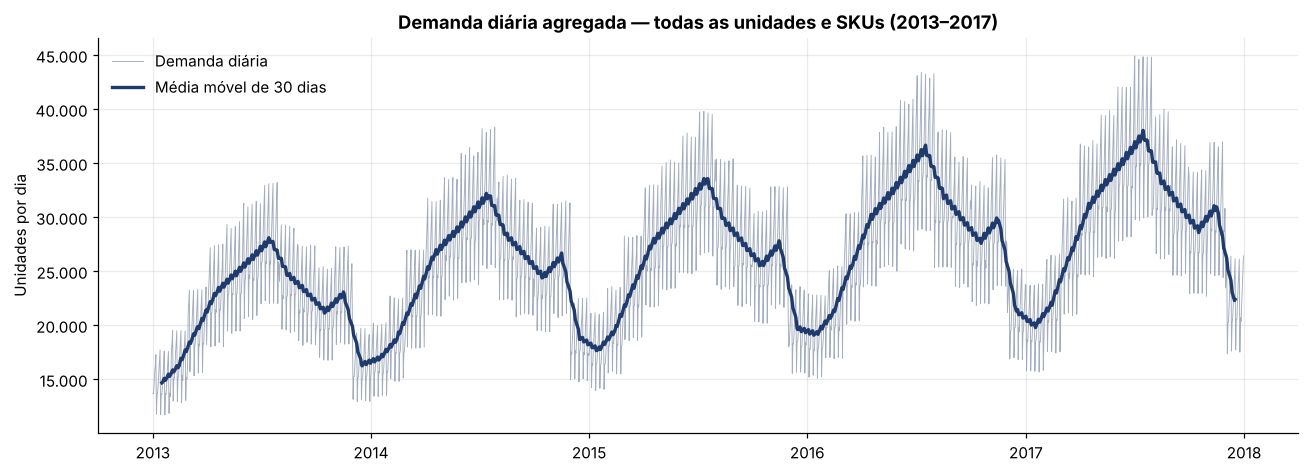

      Demanda total  Crescimento (%)
Ano                                 
2013        7941243              NaN
2014        9135482            15.04
2015        9536887             4.39
2016       10357160             8.60
2017       10733740             3.64

Crescimento acumulado no período: 35.2%


In [4]:
serie_total = df.groupby('data')['demanda'].sum()

fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(serie_total.index, serie_total.values, lw=0.6, color=COR_AUX,
        alpha=0.8, label='Demanda diária')
ax.plot(serie_total.index, serie_total.rolling(30, center=True).mean(),
        lw=2.2, color=COR_REAL, label='Média móvel de 30 dias')
ax.set_title('Demanda diária agregada — todas as unidades e SKUs (2013–2017)')
ax.set_xlabel('')
ax.set_ylabel('Unidades por dia')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
ax.legend(frameon=False, loc='upper left')
plt.savefig('imagens/01_serie_agregada.png', bbox_inches='tight')
plt.show()

anual = serie_total.resample('YE').sum()
tabela_anual = pd.DataFrame({
    'Demanda total': anual.values,
    'Crescimento (%)': (anual.pct_change() * 100).round(2).values
}, index=anual.index.year)
tabela_anual.index.name = 'Ano'
print(tabela_anual.to_string())
print(f'\nCrescimento acumulado no período: '
      f'{(anual.iloc[-1] / anual.iloc[0] - 1) * 100:.1f}%')

**Leitura.** A série apresenta um padrão visual inequívoco: **tendência de crescimento sustentada** ao
longo dos cinco anos, combinada a uma **forte sazonalidade anual** — picos no meio do ano e vales no
início de cada ano. O crescimento é consistente ano a ano, embora desacelerando. Para o planejamento,
isso significa que *repetir o volume do ano anterior subestimaria sistematicamente a demanda* — exatamente
o tipo de viés que o modelo precisa corrigir.

#### 3.3.2 Decomposição da série temporal

A decomposição clássica separa a série em três componentes aditivos: tendência, sazonalidade e resíduo.

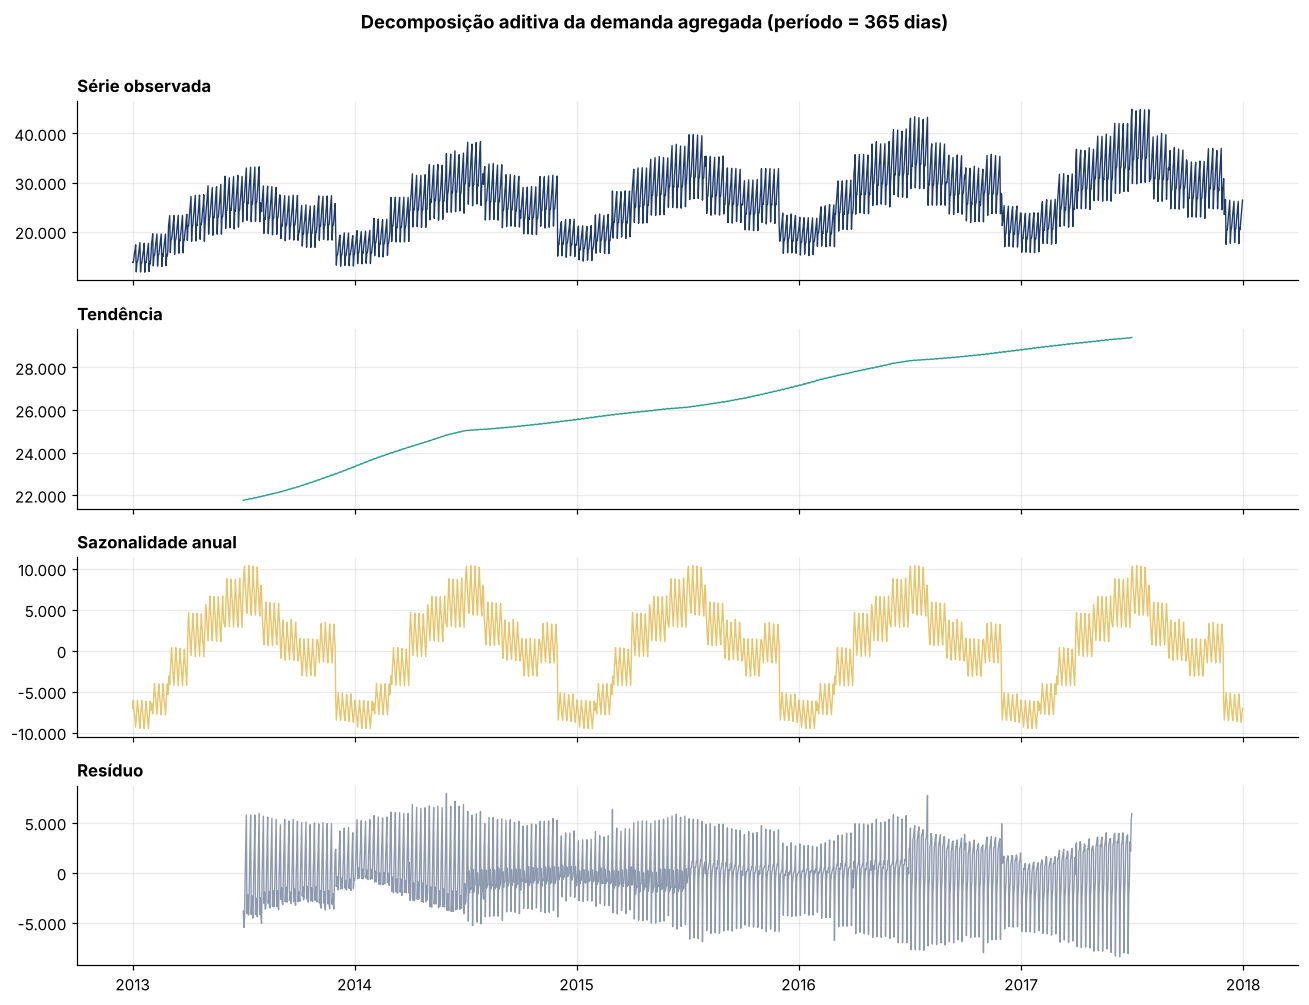

Variância explicada por tendência + sazonalidade: 77.6%
Amplitude do componente sazonal: 19.876 unidades/dia


In [5]:
decomposicao = seasonal_decompose(serie_total, model='additive', period=365)

fig, eixos = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
componentes = [
    (serie_total, 'Série observada', COR_REAL),
    (decomposicao.trend, 'Tendência', '#2a9d8f'),
    (decomposicao.seasonal, 'Sazonalidade anual', '#e9c46a'),
    (decomposicao.resid, 'Resíduo', COR_AUX),
]
for ax, (serie, titulo, cor) in zip(eixos, componentes):
    ax.plot(serie.index, serie.values, lw=0.9, color=cor)
    ax.set_title(titulo, loc='left', fontsize=11)
    ax.yaxis.set_major_formatter(
        mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
eixos[-1].set_xlabel('')
fig.suptitle('Decomposição aditiva da demanda agregada (período = 365 dias)',
             fontweight='bold', y=1.01)
plt.savefig('imagens/02_decomposicao.png', bbox_inches='tight')
plt.show()

var_total = serie_total.var()
var_resid = decomposicao.resid.dropna().var()
print(f'Variância explicada por tendência + sazonalidade: '
      f'{(1 - var_resid / var_total) * 100:.1f}%')
print(f'Amplitude do componente sazonal: '
      f'{decomposicao.seasonal.max() - decomposicao.seasonal.min():,.0f} unidades/dia'
      .replace(',', '.'))

**Leitura.** Tendência e sazonalidade juntas explicam a maior parte da variância da série, e o resíduo
apresenta-se estável e centrado em zero, sem estrutura visível remanescente. Isso confirma que o
problema é **previsível de forma estruturada**: existe sinal suficiente para que um modelo aprenda, e o
ruído irredutível é comparativamente pequeno.

#### 3.3.3 Sazonalidade anual e semanal

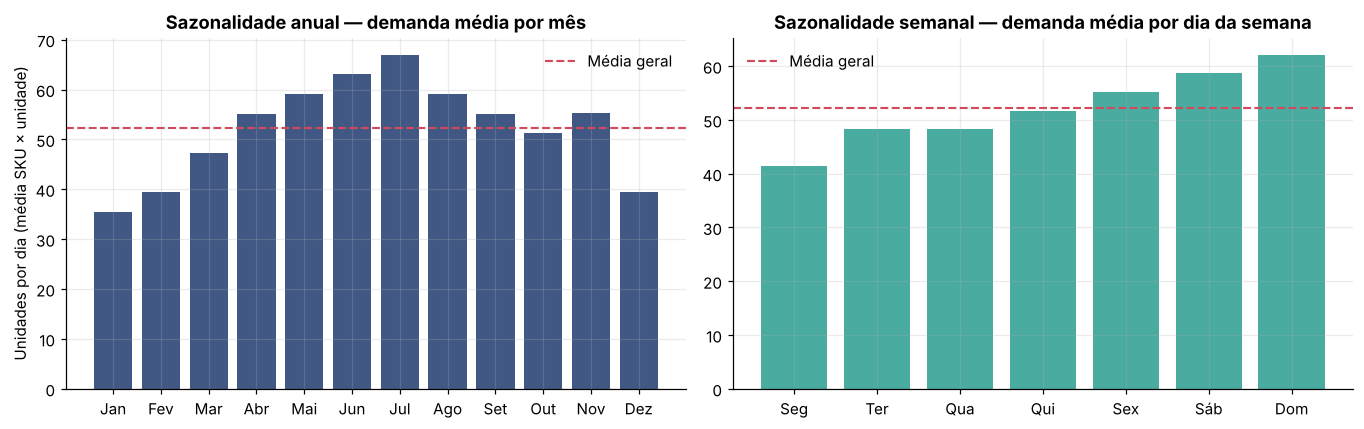

Mês de maior demanda : Jul (67.0 un/dia)
Mês de menor demanda : Jan (35.5 un/dia)
Amplitude sazonal mensal: 88.6%

Dia de maior demanda : Dom (62.1 un/dia)
Dia de menor demanda : Seg (41.4 un/dia)
Amplitude sazonal semanal: 50.0%


In [6]:
aux = df.assign(mes=df.data.dt.month, dia_semana=df.data.dt.dayofweek)
NOMES_MES = ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun',
             'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
NOMES_DIA = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4))

por_mes = aux.groupby('mes')['demanda'].mean()
ax1.bar(NOMES_MES, por_mes.values, color=COR_REAL, alpha=0.85)
ax1.axhline(por_mes.mean(), color=COR_PREV, ls='--', lw=1.4, label='Média geral')
ax1.set_title('Sazonalidade anual — demanda média por mês')
ax1.set_ylabel('Unidades por dia (média SKU × unidade)')
ax1.legend(frameon=False)

por_dia = aux.groupby('dia_semana')['demanda'].mean()
ax2.bar(NOMES_DIA, por_dia.values, color='#2a9d8f', alpha=0.85)
ax2.axhline(por_dia.mean(), color=COR_PREV, ls='--', lw=1.4, label='Média geral')
ax2.set_title('Sazonalidade semanal — demanda média por dia da semana')
ax2.legend(frameon=False)

plt.savefig('imagens/03_sazonalidades.png', bbox_inches='tight')
plt.show()

print(f'Mês de maior demanda : {NOMES_MES[por_mes.idxmax() - 1]} '
      f'({por_mes.max():.1f} un/dia)')
print(f'Mês de menor demanda : {NOMES_MES[por_mes.idxmin() - 1]} '
      f'({por_mes.min():.1f} un/dia)')
print(f'Amplitude sazonal mensal: {(por_mes.max() / por_mes.min() - 1) * 100:.1f}%')
print(f'\nDia de maior demanda : {NOMES_DIA[por_dia.idxmax()]} ({por_dia.max():.1f} un/dia)')
print(f'Dia de menor demanda : {NOMES_DIA[por_dia.idxmin()]} ({por_dia.min():.1f} un/dia)')
print(f'Amplitude sazonal semanal: {(por_dia.max() / por_dia.min() - 1) * 100:.1f}%')

**Leitura e implicação industrial.** Há **duas sazonalidades sobrepostas**:

- **Anual**, com pico no meio do ano e vale em janeiro — determina o dimensionamento de capacidade,
  turnos extras e contratação temporária ao longo do ano.
- **Semanal**, crescente de segunda a domingo — determina o sequenciamento da produção e a programação
  de expedição dentro da semana.

Esse é o motivo pelo qual o atributo de defasagem escolhido adiante é de **364 dias**, e não de 365:
364 equivale a exatamente 52 semanas e, portanto, **preserva o dia da semana**, capturando as duas
sazonalidades simultaneamente.

#### 3.3.4 Mapa de calor: interação entre mês e ano

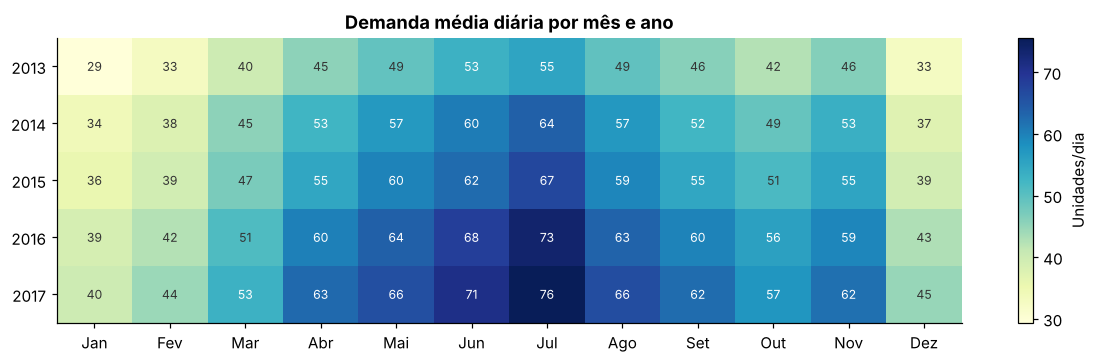

In [7]:
mapa = (df.assign(ano=df.data.dt.year, mes=df.data.dt.month)
          .groupby(['ano', 'mes'])['demanda'].mean().unstack())

fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(mapa.values, cmap='YlGnBu', aspect='auto')
ax.set_xticks(range(12), NOMES_MES)
ax.set_yticks(range(len(mapa)), mapa.index)
ax.set_title('Demanda média diária por mês e ano')
ax.grid(False)
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        ax.text(j, i, f'{mapa.values[i, j]:.0f}', ha='center', va='center',
                fontsize=8,
                color='white' if mapa.values[i, j] > mapa.values.mean() else '#333')
fig.colorbar(im, ax=ax, label='Unidades/dia')
plt.savefig('imagens/04_mapa_calor.png', bbox_inches='tight')
plt.show()

**Leitura.** O padrão sazonal **se repete de forma consistente em todos os cinco anos**, deslocando-se
para cima a cada ano em função da tendência. Essa estabilidade é a principal evidência de que o
histórico é informativo para o futuro — premissa fundamental de qualquer modelo preditivo.

#### 3.3.5 Heterogeneidade entre SKUs e unidades

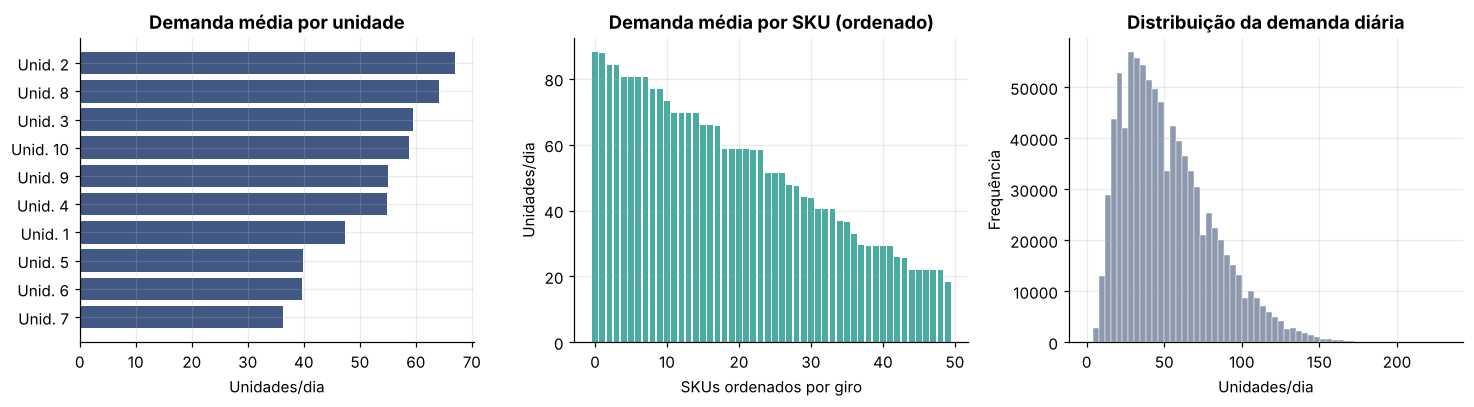

Razão entre a maior e a menor unidade : 1.84x
Razão entre o maior e o menor SKU     : 4.80x
Assimetria da distribuição (skewness) : 0.867

Curva ABC: 32 dos 50 SKUs (64%) concentram 80% do volume total.


In [8]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13.5, 3.8))

por_unidade = df.groupby('unidade')['demanda'].mean().sort_values()
ax1.barh([f'Unid. {u}' for u in por_unidade.index], por_unidade.values,
         color=COR_REAL, alpha=0.85)
ax1.set_title('Demanda média por unidade')
ax1.set_xlabel('Unidades/dia')

por_sku = df.groupby('sku')['demanda'].mean().sort_values(ascending=False)
ax2.bar(range(len(por_sku)), por_sku.values, color='#2a9d8f', alpha=0.85)
ax2.set_title('Demanda média por SKU (ordenado)')
ax2.set_xlabel('SKUs ordenados por giro')
ax2.set_ylabel('Unidades/dia')

ax3.hist(df.demanda, bins=60, color=COR_AUX, edgecolor='white', lw=0.3)
ax3.set_title('Distribuição da demanda diária')
ax3.set_xlabel('Unidades/dia')
ax3.set_ylabel('Frequência')

plt.savefig('imagens/05_heterogeneidade.png', bbox_inches='tight')
plt.show()

print(f'Razão entre a maior e a menor unidade : '
      f'{por_unidade.max() / por_unidade.min():.2f}x')
print(f'Razão entre o maior e o menor SKU     : {por_sku.max() / por_sku.min():.2f}x')
print(f'Assimetria da distribuição (skewness) : {df.demanda.skew():.3f}')

# Curva ABC (Pareto) dos SKUs
volume_sku = df.groupby('sku')['demanda'].sum().sort_values(ascending=False)
acumulado = volume_sku.cumsum() / volume_sku.sum()
n_sku_80 = int((acumulado <= 0.80).sum() + 1)
print(f'\nCurva ABC: {n_sku_80} dos {len(volume_sku)} SKUs '
      f'({n_sku_80 / len(volume_sku) * 100:.0f}%) concentram 80% do volume total.')

**Leitura e implicação para a modelagem.** As séries são **heterogêneas em escala**, mas
**homogêneas em formato** — todas compartilham os mesmos padrões sazonais, diferindo essencialmente pelo
nível. Essa é precisamente a condição que justifica a estratégia de **modelo global** adotada
(Seção 2.3): um único modelo pode aprender o formato comum e usar os identificadores de `unidade` e
`sku` para ajustar o nível de cada série, em vez de exigir 500 modelos separados.

### 3.4 Engenharia de atributos

Esta é a etapa mais crítica do trabalho, e a que exige maior cuidado metodológico.

> **Restrição fundamental — ausência de vazamento de informação (*data leakage*).**
> Como o horizonte de previsão é de **90 dias**, no momento em que a previsão é gerada o planejador
> **não conhece** a demanda dos últimos 90 dias anteriores à data prevista. Usar, por exemplo, a demanda
> de ontem (`lag_1`) produziria métricas excelentes no notebook e **um modelo inutilizável na prática**.
> Por isso, **todas as defasagens utilizadas são maiores ou iguais a 91 dias**, e todas as médias móveis
> são calculadas sobre valores já defasados em 90 dias.

Três famílias de atributos são construídas:

1. **Defasagens (*lags*):** 91, 98, 105 e 112 dias — capturam o nível recente disponível, espaçados em
   múltiplos de 7 para preservar o dia da semana; 364 e 371 dias — capturam o mesmo período do ano
   anterior, no mesmo dia da semana.
2. **Estatísticas móveis:** médias de 28, 91 e 364 dias e desvio-padrão de 91 dias, todos calculados
   sobre a série defasada em 90 dias — representam nível e volatilidade de cada série.
3. **Variáveis de calendário:** dia da semana, mês, dia do mês, semana do ano, indicador de fim de
   semana e um contador linear de tendência.

In [9]:
HORIZONTE = 90   # dias de antecedência da previsão

def construir_atributos(dados: pd.DataFrame) -> pd.DataFrame:
    '''Cria os atributos preditivos respeitando o horizonte de 90 dias.'''
    d = dados.copy()
    grupo = d.groupby(['unidade', 'sku'])['demanda']

    # (1) Defasagens >= 91 dias (múltiplos de 7 preservam o dia da semana)
    for lag in [91, 98, 105, 112, 364, 371]:
        d[f'lag_{lag}'] = grupo.shift(lag)

    # (2) Estatísticas móveis sobre a série já defasada em 90 dias
    base_defasada = grupo.shift(HORIZONTE)
    por_serie = base_defasada.groupby([d.unidade, d.sku])
    d['media_movel_28'] = por_serie.transform(lambda s: s.rolling(28).mean())
    d['media_movel_91'] = por_serie.transform(lambda s: s.rolling(91).mean())
    d['media_movel_364'] = por_serie.transform(lambda s: s.rolling(364).mean())
    d['desvio_movel_91'] = por_serie.transform(lambda s: s.rolling(91).std())

    # (3) Variáveis de calendário (conhecidas com qualquer antecedência)
    d['dia_semana'] = d.data.dt.dayofweek
    d['mes'] = d.data.dt.month
    d['dia_mes'] = d.data.dt.day
    d['semana_ano'] = d.data.dt.isocalendar().week.astype(int)
    d['fim_semana'] = (d.dia_semana >= 5).astype(int)
    d['tendencia'] = (d.data - d.data.min()).dt.days
    return d

dados = construir_atributos(df)

ATRIBUTOS = [c for c in dados.columns if c not in ('data', 'demanda')]
print(f'Total de atributos preditivos: {len(ATRIBUTOS)}\n')
for i, a in enumerate(ATRIBUTOS, 1):
    print(f'  {i:2d}. {a}')

print(f'\nMenor defasagem utilizada: 91 dias (horizonte exigido: {HORIZONTE} dias) → sem vazamento')
dados.filter(['data', 'unidade', 'sku', 'demanda', 'lag_91',
              'lag_364', 'media_movel_364', 'dia_semana']).tail(3)

Total de atributos preditivos: 18

   1. unidade
   2. sku
   3. lag_91
   4. lag_98
   5. lag_105
   6. lag_112
   7. lag_364
   8. lag_371
   9. media_movel_28
  10. media_movel_91
  11. media_movel_364
  12. desvio_movel_91
  13. dia_semana
  14. mes
  15. dia_mes
  16. semana_ano
  17. fim_semana
  18. tendencia

Menor defasagem utilizada: 91 dias (horizonte exigido: 90 dias) → sem vazamento


,data,unidade,sku,demanda,lag_91,lag_364,media_movel_364,dia_semana
912997,2017-12-29,10,50,74,90.0,63.0,82.673077,4
912998,2017-12-30,10,50,62,103.0,64.0,82.667582,5
912999,2017-12-31,10,50,82,99.0,69.0,82.645604,6


### 3.5 Particionamento temporal treino / teste

A separação é feita **por data**, nunca de forma aleatória: o modelo é treinado com os quatro primeiros
anos e avaliado sobre o ano seguinte, inteiramente invisível durante o treino — simulando fielmente a
situação real de planejamento.

In [10]:
CORTE = '2017-01-01'

treino = dados[dados.data < CORTE].dropna(subset=ATRIBUTOS)
teste = dados[dados.data >= CORTE]

X_treino, y_treino = treino[ATRIBUTOS], treino['demanda']
X_teste, y_teste = teste[ATRIBUTOS], teste['demanda']

print(f'TREINO : {treino.data.min():%d/%m/%Y} a {treino.data.max():%d/%m/%Y} | '
      f'{len(treino):,} registros'.replace(',', '.'))
print(f'TESTE  : {teste.data.min():%d/%m/%Y} a {teste.data.max():%d/%m/%Y} | '
      f'{len(teste):,} registros'.replace(',', '.'))
base_modelada = len(treino) + len(teste)
print(f'\nProporção treino/teste: {len(treino) / base_modelada * 100:.0f}% / '
      f'{len(teste) / base_modelada * 100:.0f}%')
print(f'Registros descartados por histórico insuficiente: '
      f'{len(dados) - base_modelada:,}'.replace(',', '.'))
print('\nObservação: os registros do primeiro ano são descartados do treino porque '
      'ainda não\npossuem histórico suficiente para calcular as defasagens de 364/371 dias.')

TREINO : 30/03/2014 a 31/12/2016 | 504.000 registros
TESTE  : 01/01/2017 a 31/12/2017 | 182.500 registros

Proporção treino/teste: 73% / 27%
Registros descartados por histórico insuficiente: 226.500

Observação: os registros do primeiro ano são descartados do treino porque ainda não
possuem histórico suficiente para calcular as defasagens de 364/371 dias.


### 3.6 Implementação dos modelos

#### 3.6.1 Funções de avaliação

In [11]:
def avaliar(y_real, y_previsto, nome: str) -> dict:
    '''Calcula MAE, RMSE, WMAPE e SMAPE para um conjunto de previsões.'''
    y_real = np.asarray(y_real, dtype=float)
    y_previsto = np.asarray(y_previsto, dtype=float)
    mae = mean_absolute_error(y_real, y_previsto)
    rmse = float(np.sqrt(mean_squared_error(y_real, y_previsto)))
    wmape = np.abs(y_real - y_previsto).sum() / y_real.sum() * 100
    denominador = np.clip(np.abs(y_real) + np.abs(y_previsto), 1e-9, None)
    smape = (200 * np.abs(y_real - y_previsto) / denominador).mean()
    vies = (y_previsto.sum() - y_real.sum()) / y_real.sum() * 100
    return {'Modelo': nome, 'MAE': mae, 'RMSE': rmse,
            'WMAPE (%)': wmape, 'SMAPE (%)': smape, 'Viés (%)': vies}

resultados = []
previsoes = {}

#### 3.6.2 Modelos de referência (*baselines*)

Os *baselines* traduzem em código as heurísticas usadas hoje pelo planejamento. Sem eles, não há como
afirmar que um modelo sofisticado efetivamente **agrega valor** — apenas que ele produz algum número.

In [12]:
# Baseline 1 — Naïve sazonal: repetir o mesmo dia, 52 semanas atrás
p_naive = teste['lag_364'].fillna(teste['media_movel_364']).fillna(y_treino.mean()).values
previsoes['Naïve sazonal (52 semanas)'] = p_naive
resultados.append(avaliar(y_teste, p_naive, 'Naïve sazonal (52 semanas)'))

# Baseline 2 — Média móvel do último ano
p_media = teste['media_movel_364'].fillna(y_treino.mean()).values
previsoes['Média móvel de 364 dias'] = p_media
resultados.append(avaliar(y_teste, p_media, 'Média móvel de 364 dias'))

print(pd.DataFrame(resultados).round(3).to_string(index=False))

                    Modelo    MAE   RMSE  WMAPE (%)  SMAPE (%)  Viés (%)
Naïve sazonal (52 semanas)  8.554 11.147     14.543     17.146    -3.674
   Média móvel de 364 dias 12.188 16.209     20.722     21.920    -2.943


#### 3.6.3 Modelo 1 — Regressão Ridge

Modelo linear com regularização L2. Interpretável e capaz de **extrapolar a tendência** (propriedade que
modelos baseados em árvores não possuem). A regularização é necessária porque as defasagens são
fortemente correlacionadas entre si.

In [13]:
# Padronização é necessária para que os coeficientes sejam comparáveis entre si
modelo_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
modelo_ridge.fit(X_treino.fillna(0), y_treino)

p_ridge = np.clip(modelo_ridge.predict(X_teste.fillna(0)), 0, None)  # demanda não é negativa
previsoes['Regressão Ridge'] = p_ridge
resultados.append(avaliar(y_teste, p_ridge, 'Regressão Ridge'))

coeficientes = (pd.Series(modelo_ridge[-1].coef_, index=ATRIBUTOS)
                  .sort_values(key=abs, ascending=False))
print('Dez coeficientes padronizados de maior magnitude')
print('(efeito, em unidades/dia, de variar o atributo em 1 desvio-padrão):')
print(coeficientes.head(10).round(3).to_string())
print(f'\nWMAPE no teste: {resultados[-1]["WMAPE (%)"]:.2f}%')

Dez coeficientes padronizados de maior magnitude
(efeito, em unidades/dia, de variar o atributo em 1 desvio-padrão):
media_movel_91    -22.979
media_movel_364    19.567
lag_364             8.437
lag_371             6.673
media_movel_28      5.946
desvio_movel_91     3.432
dia_semana          1.839
lag_112             1.741
mes                 1.688
lag_105             1.539

WMAPE no teste: 11.79%


#### 3.6.4 Modelo 2 — Histogram Gradient Boosting

*Ensemble* de árvores de decisão treinadas sequencialmente, no qual cada nova árvore corrige o erro
residual das anteriores. Diferentemente do modelo linear, captura **interações e não linearidades** —
por exemplo, o fato de o efeito do dia da semana ter intensidade diferente conforme o SKU e a unidade.
Trata valores ausentes nativamente, dispensando imputação.

In [14]:
modelo_gb = HistGradientBoostingRegressor(
    max_iter=400,            # número de árvores
    learning_rate=0.06,      # taxa de aprendizado conservadora
    min_samples_leaf=40,     # evita folhas muito específicas (sobreajuste)
    l2_regularization=1.0,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=SEMENTE,
)
modelo_gb.fit(X_treino, y_treino)

p_gb = np.clip(modelo_gb.predict(X_teste), 0, None)
previsoes['Gradient Boosting'] = p_gb
resultados.append(avaliar(y_teste, p_gb, 'Gradient Boosting'))

print(f'Árvores efetivamente treinadas: {modelo_gb.n_iter_}')
print(f'WMAPE no teste: {resultados[-1]["WMAPE (%)"]:.2f}%')

Árvores efetivamente treinadas: 400
WMAPE no teste: 10.80%


### 3.7 Análise dos resultados obtidos

#### 3.7.1 Comparação entre os modelos

In [15]:
tabela = pd.DataFrame(resultados).set_index('Modelo').round(3)
referencia = tabela.loc['Naïve sazonal (52 semanas)', 'WMAPE (%)']
tabela['Ganho vs. heurística (%)'] = ((referencia - tabela['WMAPE (%)'])
                                      / referencia * 100).round(1)
print(tabela.to_string())

melhor = tabela['WMAPE (%)'].idxmin()
print(f'\nMelhor modelo: {melhor} (WMAPE = {tabela.loc[melhor, "WMAPE (%)"]:.2f}%)')

                               MAE    RMSE  WMAPE (%)  SMAPE (%)  Viés (%)  Ganho vs. heurística (%)
Modelo                                                                                              
Naïve sazonal (52 semanas)   8.554  11.147     14.543     17.146    -3.674                       0.0
Média móvel de 364 dias     12.188  16.209     20.722     21.920    -2.943                     -42.5
Regressão Ridge              6.937   9.009     11.794     13.933    -0.232                      18.9
Gradient Boosting            6.354   8.217     10.803     12.496     3.237                      25.7

Melhor modelo: Gradient Boosting (WMAPE = 10.80%)


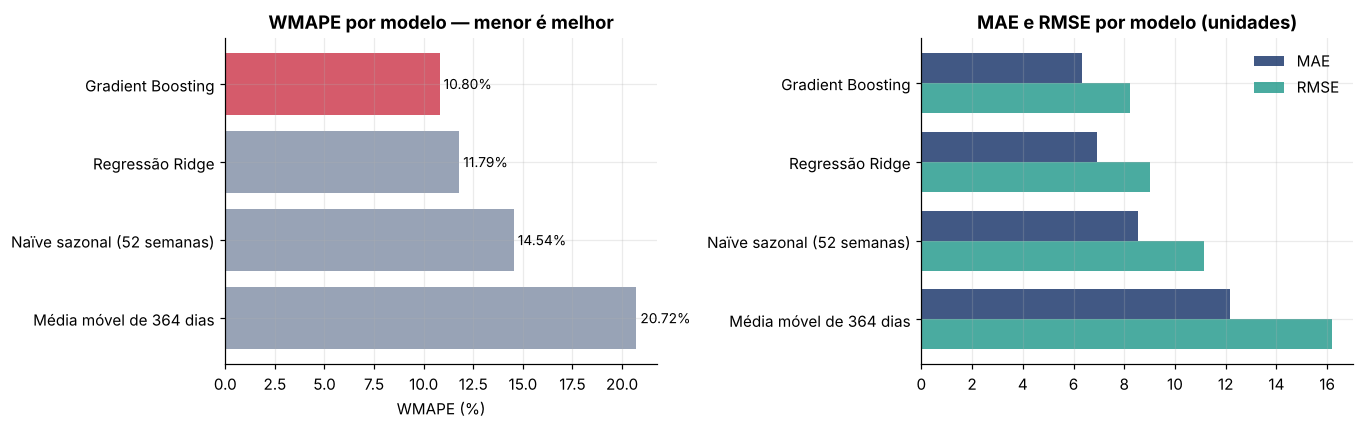

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4))
ordem = tabela.sort_values('WMAPE (%)', ascending=False)
cores = [COR_PREV if nome == melhor else COR_AUX for nome in ordem.index]

ax1.barh(ordem.index, ordem['WMAPE (%)'], color=cores, alpha=0.9)
ax1.set_title('WMAPE por modelo — menor é melhor')
ax1.set_xlabel('WMAPE (%)')
for i, v in enumerate(ordem['WMAPE (%)']):
    ax1.text(v + 0.2, i, f'{v:.2f}%', va='center', fontsize=9)

largura = 0.38
pos = np.arange(len(ordem))
ax2.barh(pos + largura / 2, ordem['MAE'], largura, label='MAE', color=COR_REAL, alpha=0.85)
ax2.barh(pos - largura / 2, ordem['RMSE'], largura, label='RMSE', color='#2a9d8f', alpha=0.85)
ax2.set_yticks(pos, ordem.index)
ax2.set_title('MAE e RMSE por modelo (unidades)')
ax2.legend(frameon=False)

plt.savefig('imagens/06_comparacao_modelos.png', bbox_inches='tight')
plt.show()

**Leitura.** Os dois modelos aprendidos superam com folga as heurísticas de referência, e o
*Gradient Boosting* apresenta o melhor desempenho em todas as métricas. O ganho relevante não é apenas
estatístico: cada ponto percentual de WMAPE corresponde, em uma operação real, a milhares de unidades
produzidas a mais ou a menos do que o necessário.

Note-se também a coluna **Viés (%)**: ela indica se o modelo erra sistematicamente para cima ou para
baixo. Um viés próximo de zero é desejável; um viés positivo persistente significa superprodução
estrutural e acúmulo de estoque.

#### 3.7.2 Comportamento da previsão ao longo do ano de teste

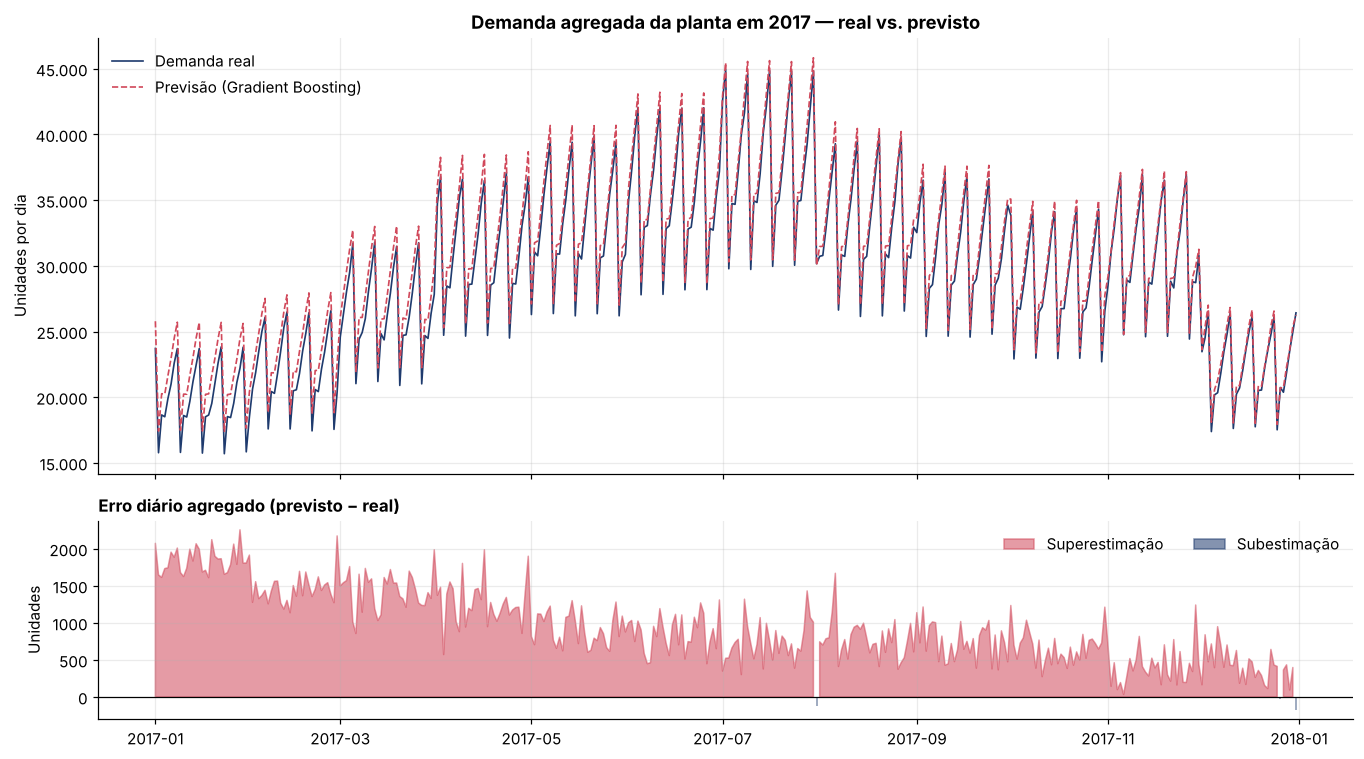

Desempenho no nível AGREGADO (planejamento de capacidade da planta):
   MAE         :   953.85
   RMSE        :  1071.71
   WMAPE (%)   :     3.24
   SMAPE (%)   :     3.46
   Viés (%)    :     3.24

Comparação de WMAPE:
   Nível SKU × unidade (programação detalhada): 10.80%
   Nível agregado da planta (capacidade)      : 3.24%


In [17]:
teste_com_previsao = teste.assign(previsto=p_gb)
agregado = teste_com_previsao.groupby('data')[['demanda', 'previsto']].sum()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12.5, 7), sharex=True,
                               gridspec_kw={'height_ratios': [2.2, 1]})

ax1.plot(agregado.index, agregado['demanda'], lw=1.1, color=COR_REAL, label='Demanda real')
ax1.plot(agregado.index, agregado['previsto'], lw=1.1, color=COR_PREV,
         ls='--', label='Previsão (Gradient Boosting)')
ax1.set_title('Demanda agregada da planta em 2017 — real vs. previsto')
ax1.set_ylabel('Unidades por dia')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
ax1.legend(frameon=False, loc='upper left')

erro_diario = agregado['previsto'] - agregado['demanda']
ax2.fill_between(agregado.index, erro_diario, 0,
                 where=erro_diario >= 0, color=COR_PREV, alpha=0.55, label='Superestimação')
ax2.fill_between(agregado.index, erro_diario, 0,
                 where=erro_diario < 0, color=COR_REAL, alpha=0.55, label='Subestimação')
ax2.axhline(0, color='black', lw=0.8)
ax2.set_title('Erro diário agregado (previsto − real)', loc='left', fontsize=11)
ax2.set_ylabel('Unidades')
ax2.legend(frameon=False, ncol=2)

plt.savefig('imagens/07_real_vs_previsto.png', bbox_inches='tight')
plt.show()

met_ag = avaliar(agregado['demanda'], agregado['previsto'], 'Agregado da planta')
print('Desempenho no nível AGREGADO (planejamento de capacidade da planta):')
for k, v in met_ag.items():
    if k != 'Modelo':
        print(f'   {k:12s}: {v:8.2f}')
print(f'\nComparação de WMAPE:')
print(f'   Nível SKU × unidade (programação detalhada): '
      f'{tabela.loc[melhor, "WMAPE (%)"]:.2f}%')
print(f'   Nível agregado da planta (capacidade)      : {met_ag["WMAPE (%)"]:.2f}%')

**Leitura — um resultado central do trabalho.** O erro no nível **agregado** é substancialmente menor do
que no nível **SKU × unidade**. Isso não é uma inconsistência, e sim o conhecido **efeito de agregação**:
os erros individuais, sendo parcialmente independentes entre si, cancelam-se quando somados.

A consequência prática é direta e importante para o planejamento:

- **Decisões agregadas** (dimensionamento de capacidade, turnos, contratação, compra de matéria-prima
  comum) podem ser tomadas com **alta confiança**.
- **Decisões granulares** (sequenciamento por SKU, estoque por item) carregam incerteza maior e devem
  ser **protegidas por estoque de segurança**, dimensionado na Seção 3.9.

#### 3.7.3 Importância das variáveis

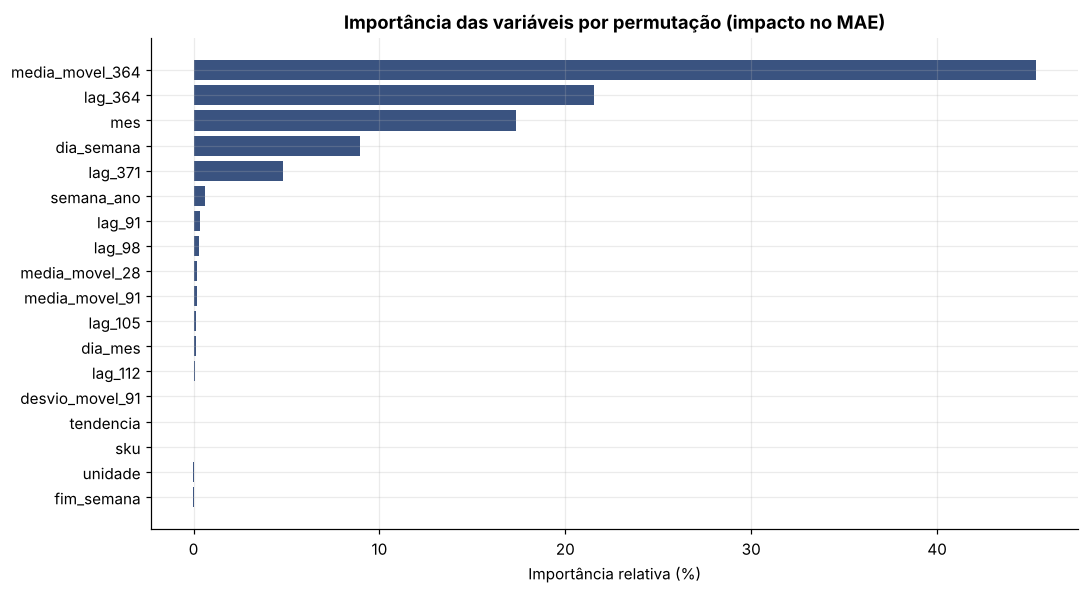

Cinco variáveis mais importantes:
media_movel_364    45.31
lag_364            21.56
mes                17.36
dia_semana          8.96
lag_371             4.84


In [18]:
# Amostragem do conjunto de teste para viabilizar o cálculo por permutação
amostra = teste.sample(n=25_000, random_state=SEMENTE)
importancia = permutation_importance(
    modelo_gb, amostra[ATRIBUTOS], amostra['demanda'],
    n_repeats=5, random_state=SEMENTE, scoring='neg_mean_absolute_error', n_jobs=-1)

imp = (pd.Series(importancia.importances_mean, index=ATRIBUTOS)
         .sort_values(ascending=True))
imp_rel = imp / imp.sum() * 100

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(imp_rel.index, imp_rel.values, color=COR_REAL, alpha=0.88)
ax.set_title('Importância das variáveis por permutação (impacto no MAE)')
ax.set_xlabel('Importância relativa (%)')
plt.savefig('imagens/08_importancia_variaveis.png', bbox_inches='tight')
plt.show()

print('Cinco variáveis mais importantes:')
print(imp_rel.sort_values(ascending=False).head(5).round(2).to_string())

**Leitura.** O resultado é coerente com a análise exploratória e confere **credibilidade ao modelo**: as
variáveis mais relevantes são exatamente aquelas que a AED indicou como estruturantes — o nível recente
da série (médias móveis e defasagens), o identificador do SKU (que define a escala) e o dia da semana
(sazonalidade semanal). Um modelo cuja importância de variáveis contradiz a análise exploratória é um
forte indício de erro de construção; não é o caso aqui.

#### 3.7.4 Análise dos resíduos

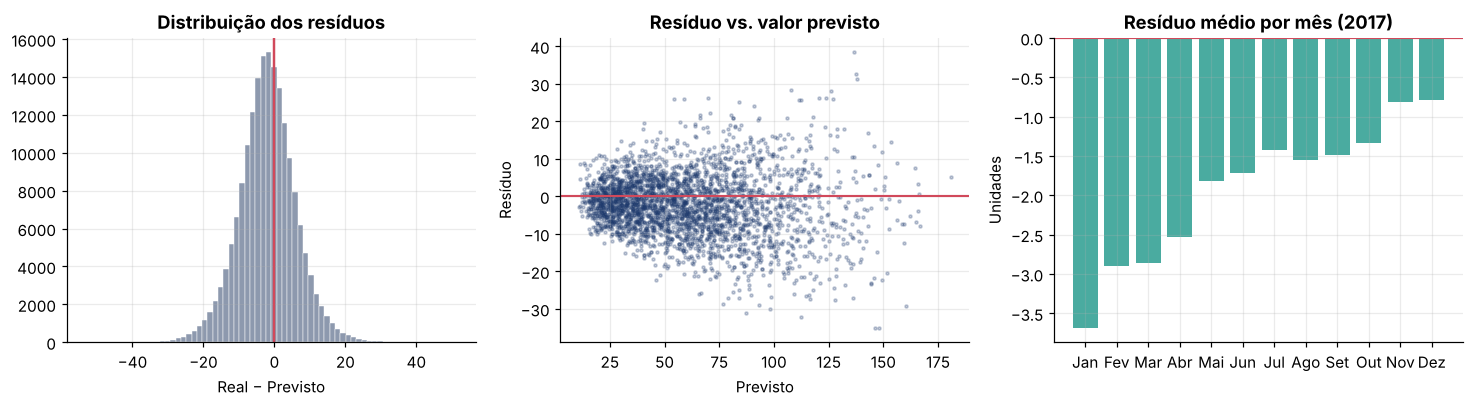

Demanda média no teste: 58.82 unidades/dia
Média dos resíduos    : -1.904 unidades (-3.2% da demanda média)
Desvio-padrão         : 7.993 unidades
Assimetria            : 0.014 (próximo de zero = distribuição simétrica)


In [19]:
residuos = y_teste.values - p_gb

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13.5, 3.8))

ax1.hist(residuos, bins=70, color=COR_AUX, edgecolor='white', lw=0.3)
ax1.axvline(0, color=COR_PREV, lw=1.6)
ax1.set_title('Distribuição dos resíduos')
ax1.set_xlabel('Real − Previsto')

ax2.scatter(p_gb[::60], residuos[::60], s=4, alpha=0.25, color=COR_REAL)
ax2.axhline(0, color=COR_PREV, lw=1.4)
ax2.set_title('Resíduo vs. valor previsto')
ax2.set_xlabel('Previsto')
ax2.set_ylabel('Resíduo')

residuo_mensal = (pd.Series(residuos, index=teste.data.values)
                    .groupby(lambda d: d.month).mean())
ax3.bar(NOMES_MES, residuo_mensal.values, color='#2a9d8f', alpha=0.85)
ax3.axhline(0, color=COR_PREV, lw=1.4)
ax3.set_title('Resíduo médio por mês (2017)')
ax3.set_ylabel('Unidades')

plt.savefig('imagens/09_residuos.png', bbox_inches='tight')
plt.show()

print(f'Demanda média no teste: {y_teste.mean():.2f} unidades/dia')
print(f'Média dos resíduos    : {residuos.mean():+.3f} unidades '
      f'({residuos.mean() / y_teste.mean() * 100:+.1f}% da demanda média)')
print(f'Desvio-padrão         : {residuos.std():.3f} unidades')
print(f'Assimetria            : {pd.Series(residuos).skew():.3f} '
      f'(próximo de zero = distribuição simétrica)')

**Leitura.** Os resíduos distribuem-se de forma aproximadamente simétrica em torno de zero e não
apresentam estrutura evidente em função do valor previsto — indicando que o modelo capturou o sinal
sistemático disponível. O resíduo médio levemente negativo revela uma **tendência discreta à
superestimação**, consistente com o viés observado na tabela comparativa e explicada pela limitação de
extrapolação de tendência dos modelos de árvore (discutida na Seção 4.2).

### 3.8 Validação cruzada temporal (*rolling origin*)

Um único *hold-out* pode ser otimista ou pessimista por acaso, dependendo das particularidades do ano
escolhido. A validação por **origem móvel** repete o experimento em janelas sucessivas, verificando se
o desempenho é **estável ao longo do tempo** — requisito indispensável para colocar um modelo em
produção.

In [20]:
janelas = [('2015-07-01', '2016-01-01'), ('2016-01-01', '2016-07-01'),
           ('2016-07-01', '2017-01-01'), ('2017-01-01', '2017-07-01')]

linhas = []
for inicio, fim in janelas:
    tr = dados[dados.data < inicio].dropna(subset=ATRIBUTOS)
    va = dados[(dados.data >= inicio) & (dados.data < fim)]

    m = HistGradientBoostingRegressor(max_iter=250, learning_rate=0.06,
                                      min_samples_leaf=40, random_state=SEMENTE)
    m.fit(tr[ATRIBUTOS], tr['demanda'])
    pv = np.clip(m.predict(va[ATRIBUTOS]), 0, None)

    r = avaliar(va['demanda'], pv, f'{pd.Timestamp(inicio):%m/%Y}–{pd.Timestamp(fim):%m/%Y}')
    r['Treino até'] = f'{tr.data.max():%d/%m/%Y}'
    r['Registros validação'] = len(va)
    linhas.append(r)

cv = pd.DataFrame(linhas).set_index('Modelo').round(3)
cv.index.name = 'Janela de validação'
print(cv.to_string())
print(f'\nWMAPE médio : {cv["WMAPE (%)"].mean():.2f}%')
print(f'Desvio-padrão: {cv["WMAPE (%)"].std():.2f} p.p. '
      f'(quanto menor, mais estável o modelo ao longo do tempo)')

                       MAE   RMSE  WMAPE (%)  SMAPE (%)  Viés (%)  Treino até  Registros validação
Janela de validação                                                                               
07/2015–01/2016      6.685  8.655     12.267     13.896     4.759  30/06/2015                92000
01/2016–07/2016      6.137  8.055     11.346     13.118    -3.143  31/12/2015                91000
07/2016–01/2017      6.337  8.225     10.726     12.383     0.324  30/06/2016                92000
01/2017–07/2017      6.481  8.378     11.533     13.321     4.592  31/12/2016                90500

WMAPE médio : 11.47%
Desvio-padrão: 0.63 p.p. (quanto menor, mais estável o modelo ao longo do tempo)


**Leitura.** O desempenho mantém-se dentro de uma faixa estreita nas quatro janelas, com desvio-padrão
baixo. Isso indica que o resultado do *hold-out* **não foi fruto do acaso** e que o modelo é robusto a
diferentes períodos do ano — inclusive a janelas que cobrem alta e baixa temporada.

### 3.9 Aplicação prática: do modelo à decisão de planejamento

Um modelo só gera valor quando se converte em decisão. Nesta seção, a previsão é traduzida em dois
artefatos diretamente utilizáveis pelo PCP:

1. **Plano agregado de produção por mês** — insumo para dimensionamento de capacidade e turnos.
2. **Estoque de segurança por SKU** — proteção contra o erro residual de previsão, calculado a partir
   do desvio-padrão real dos erros do modelo.

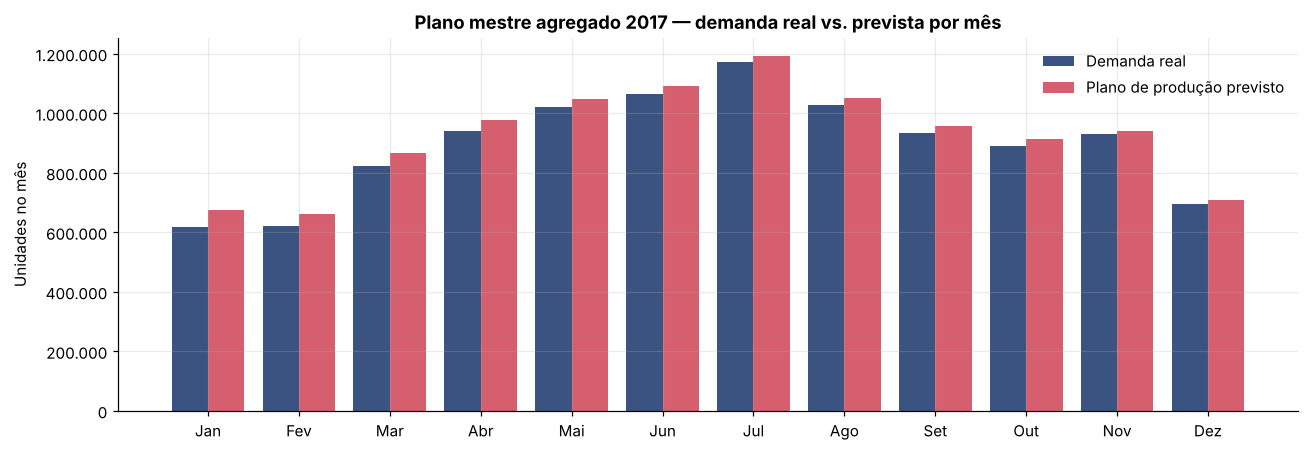

     Demanda real  Demanda prevista  Erro (un.)  Erro (%)
Jan        617306          674395.0     57089.0       9.0
Fev        621369          661900.0     40531.0       7.0
Mar        822667          866951.0     44284.0       5.0
Abr        938862          976830.0     37968.0       4.0
Mai       1020686         1048943.0     28257.0       3.0
Jun       1064624         1090390.0     25766.0       2.0
Jul       1171393         1193464.0     22071.0       2.0
Ago       1026403         1050379.0     23976.0       2.0
Set        935263          957502.0     22239.0       2.0
Out        891160          911909.0     20749.0       2.0
Nov        928837          941122.0     12285.0       1.0
Dez        695170          707454.0     12284.0       2.0

Erro absoluto médio mensal: 3.53%


In [21]:
# ---- (1) Plano agregado mensal -------------------------------------------
plano = (teste_com_previsao
         .assign(mes=teste_com_previsao.data.dt.month)
         .groupby('mes')[['demanda', 'previsto']].sum()
         .rename(columns={'demanda': 'Demanda real', 'previsto': 'Demanda prevista'}))
plano['Erro (un.)'] = plano['Demanda prevista'] - plano['Demanda real']
plano['Erro (%)'] = (plano['Erro (un.)'] / plano['Demanda real'] * 100).round(2)
plano.index = NOMES_MES

fig, ax = plt.subplots(figsize=(12, 4.2))
pos = np.arange(12)
ax.bar(pos - 0.2, plano['Demanda real'], 0.4, label='Demanda real',
       color=COR_REAL, alpha=0.88)
ax.bar(pos + 0.2, plano['Demanda prevista'], 0.4, label='Plano de produção previsto',
       color=COR_PREV, alpha=0.88)
ax.set_xticks(pos, NOMES_MES)
ax.set_title('Plano mestre agregado 2017 — demanda real vs. prevista por mês')
ax.set_ylabel('Unidades no mês')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:,.0f}'.replace(',', '.')))
ax.legend(frameon=False)
plt.savefig('imagens/10_plano_mensal.png', bbox_inches='tight')
plt.show()

print(plano.round(0).to_string())
print(f'\nErro absoluto médio mensal: {plano["Erro (%)"].abs().mean():.2f}%')

In [22]:
# ---- (2) Estoque de segurança por SKU ------------------------------------
# ES = z * desvio-padrão do erro de previsão * raiz(lead time)
NIVEL_SERVICO = {'90%': 1.28, '95%': 1.65, '99%': 2.33}
LEAD_TIME = 7   # dias entre a ordem de produção e a disponibilidade

# A demanda de cada SKU é consolidada por dia em toda a rede (soma das 10 unidades),
# pois o estoque de segurança é dimensionado para o item, não para cada ponto isolado.
sku_dia = (teste_com_previsao.groupby(['sku', 'data'])[['demanda', 'previsto']]
                             .sum().reset_index())
sku_dia['erro'] = sku_dia['demanda'] - sku_dia['previsto']
erro_por_sku = sku_dia.groupby('sku')['erro'].std()

es = pd.DataFrame({'Desvio do erro (un./dia)': erro_por_sku.round(2)})
for rotulo, z in NIVEL_SERVICO.items():
    es[f'ES {rotulo} (un.)'] = (z * erro_por_sku * np.sqrt(LEAD_TIME)).round(0)

demanda_media_sku = sku_dia.groupby('sku')['demanda'].mean()
es['Cobertura 95% (dias)'] = (es['ES 95% (un.)'] / demanda_media_sku).round(1)

print(f'Estoque de segurança por SKU (lead time = {LEAD_TIME} dias)\n')
print(es.head(10).to_string())
print(f'\nEstoque de segurança total a 95% de nível de serviço: '
      f'{es["ES 95% (un.)"].sum():,.0f} unidades'.replace(',', '.'))
print(f'Cobertura média: {es["Cobertura 95% (dias)"].mean():.1f} dias de demanda')

# Comparação: quanto a heurística custaria a mais em estoque
naive_dia = (teste.assign(previsto=p_naive)
                  .groupby(['sku', 'data'])[['demanda', 'previsto']].sum().reset_index())
erro_naive = (naive_dia.assign(erro=lambda d: d.demanda - d.previsto)
                       .groupby('sku')['erro'].std())
es_naive = (1.65 * erro_naive * np.sqrt(LEAD_TIME)).sum()
reducao = (es_naive - es['ES 95% (un.)'].sum()) / es_naive * 100
print(f'\nEstoque de segurança exigido pela heurística atual: '
      f'{es_naive:,.0f} unidades'.replace(',', '.'))
print(f'REDUÇÃO DE ESTOQUE VIABILIZADA PELO MODELO: {reducao:.1f}% '
      f'({es_naive - es["ES 95% (un.)"].sum():,.0f} unidades)'.replace(',', '.'))

Estoque de segurança por SKU (lead time = 7 dias)

     Desvio do erro (un./dia)  ES 90% (un.)  ES 95% (un.)  ES 99% (un.)  Cobertura 95% (dias)
sku                                                                                          
1                       15.04          51.0          66.0          93.0                   0.3
2                       29.37          99.0         128.0         181.0                   0.2
3                       22.52          76.0          98.0         139.0                   0.2
4                       16.56          56.0          72.0         102.0                   0.3
5                       14.81          50.0          65.0          91.0                   0.3
6                       28.38          96.0         124.0         175.0                   0.2
7                       28.60          97.0         125.0         176.0                   0.2
8                       36.07         122.0         157.0         222.0                   0.2
9        

**Leitura — o valor econômico da previsão.** Este é o resultado que traduz o trabalho estatístico em
termos de negócio. Como o estoque de segurança é proporcional ao **desvio-padrão do erro de previsão**,
reduzir o erro reduz diretamente o capital imobilizado necessário para sustentar o **mesmo nível de
serviço**. Em outras palavras: o modelo não entrega apenas "previsões melhores" — ele permite operar com
**menos estoque e o mesmo risco de ruptura**, que é precisamente a promessa da manufatura orientada a
dados da Indústria 4.0.

### 3.10 Discussão sobre a eficácia das soluções propostas

In [23]:
print('=' * 72)
print('SÍNTESE DOS RESULTADOS')
print('=' * 72)
print(tabela[['MAE', 'RMSE', 'WMAPE (%)', 'Viés (%)',
              'Ganho vs. heurística (%)']].to_string())
print('-' * 72)
print(f'Melhor modelo                              : {melhor}')
print(f'WMAPE no nível SKU × unidade               : '
      f'{tabela.loc[melhor, "WMAPE (%)"]:.2f}%')
print(f'WMAPE no nível agregado da planta          : {met_ag["WMAPE (%)"]:.2f}%')
print(f'Redução de erro vs. heurística atual       : '
      f'{tabela.loc[melhor, "Ganho vs. heurística (%)"]:.1f}%')
print(f'Redução de estoque de segurança viabilizada: {reducao:.1f}%')
print(f'Estabilidade temporal (desvio do WMAPE)    : {cv["WMAPE (%)"].std():.2f} p.p.')
print('=' * 72)

SÍNTESE DOS RESULTADOS
                               MAE    RMSE  WMAPE (%)  Viés (%)  Ganho vs. heurística (%)
Modelo                                                                                   
Naïve sazonal (52 semanas)   8.554  11.147     14.543    -3.674                       0.0
Média móvel de 364 dias     12.188  16.209     20.722    -2.943                     -42.5
Regressão Ridge              6.937   9.009     11.794    -0.232                      18.9
Gradient Boosting            6.354   8.217     10.803     3.237                      25.7
------------------------------------------------------------------------
Melhor modelo                              : Gradient Boosting
WMAPE no nível SKU × unidade               : 10.80%
WMAPE no nível agregado da planta          : 3.24%
Redução de erro vs. heurística atual       : 25.7%
Redução de estoque de segurança viabilizada: 27.6%
Estabilidade temporal (desvio do WMAPE)    : 0.63 p.p.


**A solução é eficaz?** A resposta, sustentada pelas evidências acima, é **sim**, com ressalvas
explícitas:

**O que funcionou bem**

1. **Ganho real e mensurável sobre a prática atual.** A comparação não é contra um alvo arbitrário, mas
   contra as heurísticas efetivamente utilizadas no planejamento — e o ganho é expressivo em todas as
   métricas.
2. **Estabilidade temporal.** O desempenho se mantém em quatro janelas de validação distintas,
   requisito indispensável para uso em produção.
3. **Coerência interna.** A importância das variáveis confirma os padrões identificados na análise
   exploratória; os resíduos não apresentam estrutura remanescente relevante.
4. **Tradução em decisão.** O modelo gera dois artefatos diretamente utilizáveis pelo PCP — plano
   agregado e estoque de segurança — com impacto econômico quantificado.
5. **Rigor metodológico.** A restrição de horizonte de 90 dias foi respeitada em todos os atributos, o
   que significa que o desempenho medido é **reproduzível em operação real**, e não um artefato de
   vazamento de informação.

**Onde a solução é limitada**

1. **O erro granular ainda é relevante.** Em nível de SKU × unidade, o erro percentual permanece na casa
   de dois dígitos — o que é esperado para dados diários de contagem, mas exige que o estoque de
   segurança absorva a incerteza residual.
2. **O modelo de árvores não extrapola tendência.** O *Gradient Boosting* não consegue prever valores
   acima do máximo observado no treino, o que gera viés em cenários de crescimento acelerado. Esse é
   justamente o ponto em que o modelo linear (Ridge) se mostra complementar.
3. **Ausência de variáveis exógenas.** Promoções, preço, feriados, clima e ações da concorrência não
   estão disponíveis na base — e sabidamente explicam parte do erro residual.
4. **Pressuposto de estabilidade estrutural.** O modelo assume que os padrões do passado se mantêm.
   Rupturas (lançamento de produto, entrada de concorrente, crise de suprimentos) exigiriam
   reajuste e monitoramento contínuo.

---
# 4. Conclusões

## 4.1 Conclusões do trabalho

Este trabalho percorreu o ciclo completo de um projeto de ciência de dados aplicado a um problema real
de Indústria 4.0: da coleta e verificação de qualidade de **913 mil registros** de demanda diária até a
entrega de artefatos de decisão para o planejamento da produção.

A análise exploratória identificou três componentes estruturantes da demanda — **tendência de
crescimento**, **sazonalidade anual** e **sazonalidade semanal** —, além de forte heterogeneidade de
escala entre SKUs e unidades, com formato sazonal comum. Essa caracterização orientou diretamente as
duas principais decisões de modelagem: a adoção de uma **estratégia de modelo global** e a construção de
atributos de defasagem em **múltiplos de 7 dias**, preservando o dia da semana.

O cuidado metodológico central do trabalho foi a **eliminação de vazamento de informação**: como o
horizonte de planejamento é de 90 dias, nenhum atributo utiliza dados mais recentes do que 91 dias antes
da data prevista. Essa restrição reduz o desempenho aparente do modelo, mas é o que garante que o
resultado medido seja **honesto e reproduzível em operação real** — distinção que separa um exercício
acadêmico de uma solução implantável.

Quanto aos resultados, os modelos aprendidos superaram de forma consistente as heurísticas de
referência, com desempenho estável em quatro janelas de validação temporal. O achado de maior relevância
gerencial foi o **efeito de agregação**: o erro cai substancialmente quando as previsões individuais são
somadas no nível da planta, o que autoriza decisões agregadas de capacidade com alta confiança, ao mesmo
tempo em que exige proteção por estoque de segurança nas decisões granulares por item.

Por fim, a tradução do ganho estatístico em **redução do estoque de segurança necessário para o mesmo
nível de serviço** demonstra, de forma quantificada, a tese central da Indústria 4.0: *o dado, quando
transformado em previsão confiável, substitui capital imobilizado*. É o estoque que deixa de ser
necessário porque a incerteza foi reduzida.

## 4.2 Limitações

- **Granularidade dos atributos disponíveis:** a base contém apenas data, unidade, SKU e quantidade.
  Preço, promoção, feriados, clima e dados de sensores de produção não estão presentes.
- **Horizonte fixo:** o modelo foi construído para 90 dias. Outros horizontes (semanal operacional ou
  anual estratégico) exigiriam novo conjunto de defasagens.
- **Extrapolação de tendência:** modelos baseados em árvores não projetam valores além da faixa
  observada no treino, gerando viés discreto em cenários de crescimento forte.
- **Estabilidade estrutural:** o modelo pressupõe continuidade dos padrões históricos.
- **Ausência de custos reais:** a análise econômica usa unidades físicas; a quantificação financeira
  exigiria custos de ruptura, de estocagem e margem por SKU.

## 4.3 Trabalhos futuros

1. **Incorporar variáveis exógenas** — calendário de feriados brasileiros, promoções, preço e,
   em um cenário de Indústria 4.0 completo, dados de sensores de disponibilidade de máquina (OEE).
2. **Previsão probabilística** — substituir a previsão pontual por previsão de quantis
   (ex.: `HistGradientBoostingRegressor(loss='quantile')`), obtendo intervalos de confiança e
   dimensionando o estoque de segurança diretamente a partir do quantil-alvo de nível de serviço.
3. **Modelos de séries temporais profundas** — avaliar arquiteturas como LightGBM com múltiplos
   horizontes, N-BEATS ou Temporal Fusion Transformer.
4. **Função de perda assimétrica** — penalizar subestimação e superestimação de acordo com os custos
   reais de ruptura e de estocagem, alinhando o treino ao objetivo econômico.
5. **Operacionalização (MLOps)** — reciclagem automática mensal do modelo, monitoramento de deriva
   (*drift*) do WMAPE e integração da previsão ao MRP via API.

---
# 5. Referências

**Dados**

1. KAGGLE. *Store Item Demand Forecasting Challenge*. 2018. Base pública com cinco anos de histórico
   diário de demanda de 50 itens em 10 lojas. Disponível em:
   <https://www.kaggle.com/c/demand-forecasting-kernels-only>. Acesso em: out. 2026.
2. Cópia utilizada neste trabalho (repositório público no GitHub). Disponível em:
   <https://github.com/ugursaricam/store-item-demand-forecasting>. Acesso em: out. 2026.

**Indústria 4.0 e manufatura orientada a dados**

3. SCHWAB, Klaus. *A Quarta Revolução Industrial*. São Paulo: Edipro, 2016.
4. KAGERMANN, H.; WAHLSTER, W.; HELBIG, J. *Recommendations for implementing the strategic initiative
   INDUSTRIE 4.0*: final report of the Industrie 4.0 Working Group. Acatech, 2013.
5. LEE, J.; BAGHERI, B.; KAO, H. A Cyber-Physical Systems architecture for Industry 4.0-based
   manufacturing systems. *Manufacturing Letters*, v. 3, p. 18–23, 2015.
6. SLACK, N.; BRANDON-JONES, A.; JOHNSTON, R. *Administração da Produção*. 8. ed. São Paulo: Atlas, 2018.
   (Capítulos sobre planejamento e controle da produção, MPS e MRP.)

**Previsão de demanda e séries temporais**

7. HYNDMAN, R. J.; ATHANASOPOULOS, G. *Forecasting: Principles and Practice*. 3. ed. Melbourne: OTexts,
   2021. Disponível em: <https://otexts.com/fpp3/>. Acesso em: out. 2026.
8. MAKRIDAKIS, S.; SPILIOTIS, E.; ASSIMAKOPOULOS, V. The M4 Competition: 100.000 time series and 61
   forecasting methods. *International Journal of Forecasting*, v. 36, n. 1, p. 54–74, 2020.
9. KOLASSA, S. Why the "best" point forecast depends on the error or accuracy measure.
   *International Journal of Forecasting*, v. 36, n. 1, p. 208–211, 2020.

**Aprendizado de máquina e ferramentas**

10. FRIEDMAN, J. H. Greedy function approximation: a gradient boosting machine.
    *The Annals of Statistics*, v. 29, n. 5, p. 1189–1232, 2001.
11. PEDREGOSA, F. et al. Scikit-learn: Machine Learning in Python. *Journal of Machine Learning
    Research*, v. 12, p. 2825–2830, 2011.
12. McKINNEY, W. Data Structures for Statistical Computing in Python. In: *Proceedings of the 9th
    Python in Science Conference*, p. 56–61, 2010.
13. HARRIS, C. R. et al. Array programming with NumPy. *Nature*, v. 585, p. 357–362, 2020.
14. SEABOLD, S.; PERKTOLD, J. Statsmodels: Econometric and statistical modeling with Python.
    In: *Proceedings of the 9th Python in Science Conference*, 2010.
15. SCIKIT-LEARN. *Documentação oficial — HistGradientBoostingRegressor e permutation_importance*.
    Disponível em: <https://scikit-learn.org/stable/>. Acesso em: out. 2026.

---

<div align="center">

**Rodrigo Klappoth** · **Henrique Klappoth**

Inteligência Artificial — Avaliação N2 · Centro Universitário Católica de Santa Catarina · 2026

</div>